# Ejercicio 2
### UDLA
#### Decisiones y Simulacion
#### Fecha emisión: 2026-09-22
#### Fecha entrega: 2026-09-29
##### La entrega considera un video de 3 minutos explicando claramente el código por pregunta.
## Puntaje total es 5 puntos por cada respuesta a las preguntas (75 puntos) y 25 puntos por el video.
## Para el caso del video se aplicará las mismas condiciones de los videos anteriores.

## 📊 Tabla resumen: qué mide cada pregunta
###	Pregunta	Métrica comercial	Decisión de negocios
1.	Registros únicos	Volumen de cartera	Dimensionar el mercado interno
2.	Ingreso promedio	Ticket promedio	Benchmark de compensación
3.	Distribución por ciudad	Cobertura geográfica	Expansión territorial
4.	Gasto total	Facturación interna	Presupuesto de compensaciones
5.	Estado	Base activa	Retención de talento
6.	Gasto por depto.	Mix de inversión	Priorizar presupuesto
7.	Ingreso por modalidad	Eficiencia operativa	Política de teletrabajo
8.	Top ciudades por gasto	Segmentos rentables	Foco comercial
9.	Satisfacción vs gasto	ROI de compensación	Ajuste de beneficios
10.	Tendencia anual	Evolución de costos	Proyección financiera
11.	Evaluación por depto.	Performance	Planes de mejora
12.	Segmentación por ingreso	Cliente interno	Segmentación de beneficios
13.	Top deptos. por gasto	Pareto	Priorización 80/20
14.	Ciudad × Modalidad	Rentabilidad cruzada	Optimización de recursos
15.	Exportación + resumen	Deliverable	Informe a dirección

### Nombre integrantes:
#### Catalina Armijo 
#### Catalina Garces 
#### Valeska Henners Toledo 
#### Daniela Venenciano 
#### Link Video : https://drive.google.com/file/d/1UpkzUbaXxllwJoT3pYPY0WF5SRUYwEKw/view?usp=sharing

In [4]:
# CELDA 1: Importar librerías (VS Code o en Google Colaboratory)
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os 

sns.set_style ('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
print ('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.0.3 | numpy 2.5.1


In [5]:
# CELDA 2: Leer el archivo Excel
df = pd.read_excel(r'C:\Users\Vale\Desktop\ingenieria comercial\semestre 6\desicion y simulacion\Dataset_S7.xlsx')

print('Dimensiones:', df.shape)
df.head()

Dimensiones: (360, 17)


,ID,Nombre,Apellido,Edad,Ciudad,Genero,Ingreso Mensual,Horas Trabajo Semana,Antiguedad Meses,Satisfaccion,Compras Mes,Gasto Mensual,Departamento,Modalidad,Fecha Ingreso,Estado,Evaluacion
0,1001,Sofía,Pérez,64.0,Santiago,Masculino,895864.0,48,12,6.0,11,265404,Marketing,Remoto,2020-01-01 00:00:00,Activo,1.5
1,1002,Catalina,Contreras,47.0,Concepción,femenino,742231.0,44,49,3.0,0,322523,Finanzas,Remoto,2020-01-04 00:00:00,Activo,3.8
2,1003,Javiera,Díaz,NaN,La Serena,Masculino,1155290.0,20,42,10.0,6,37297,Ventas,Presencial,2020-01-07 00:00:00,Activo,2.8
3,1004,Diego,González,65.0,Santiago,Masculino,614053.0,36,166,5.0,8,529346,Finanzas,Remoto,2020-01-10 00:00:00,Activo,5.9
4,1005,Sofía,Pérez,34.0,Valparaíso,Femenino,1043586.0,36,82,6.0,2,140234,TI,Híbrido,2020-01-13 00:00:00,Activo,1.3


In [6]:
# CELDA 3: Diagnóstico de calidad
print('=== INFORMACIÓN GENERAL - NUMERO DE COLUMNAS Y FILAS')
print('Filas:', df.shape[0], '| Columnas:', df.shape[1])

print('\n=== TIPOS DE DATOS ===')
print(df.dtypes)

print('\n=== VALORES NULOS POR COLUMNA ===')
print(df.isnull().sum())

print('\n=== DUPLICADOS ===')
print('Filas duplicadas:', df.duplicated().sum())

print('\n=== ESTADÍSTICAS NUMÉRICAS ===')
df.describe()


=== INFORMACIÓN GENERAL - NUMERO DE COLUMNAS Y FILAS
Filas: 360 | Columnas: 17

=== TIPOS DE DATOS ===
ID                        int64
Nombre                      str
Apellido                    str
Edad                    float64
Ciudad                      str
Genero                      str
Ingreso Mensual         float64
Horas Trabajo Semana      int64
Antiguedad Meses          int64
Satisfaccion            float64
Compras Mes               int64
Gasto Mensual             int64
Departamento                str
Modalidad                   str
Fecha Ingreso            object
Estado                      str
Evaluacion              float64
dtype: object

=== VALORES NULOS POR COLUMNA ===
ID                       0
Nombre                   0
Apellido                 0
Edad                    12
Ciudad                   9
Genero                   0
Ingreso Mensual         14
Horas Trabajo Semana     0
Antiguedad Meses         0
Satisfaccion             7
Compras Mes              0
Gasto M

,ID,Edad,Ingreso Mensual,Horas Trabajo Semana,Antiguedad Meses,Satisfaccion,Compras Mes,Gasto Mensual,Evaluacion
count,360.000000,348.000000,3.460000e+02,360.000000,360.000000,353.000000,360.000000,3.600000e+02,360.000000
mean,1175.727778,44.902299,1.484036e+06,34.025000,93.572222,5.665722,6.069444,3.567191e+05,4.012222
std,101.477653,22.354021,1.545736e+06,8.745357,54.088912,2.901095,3.838401,4.570166e+05,1.742446
min,1001.000000,-5.000000,4.590780e+05,20.000000,2.000000,1.000000,0.000000,2.015900e+04,1.000000
25%,1087.750000,30.000000,9.015922e+05,26.000000,42.750000,3.000000,3.000000,1.763698e+05,2.500000
50%,1175.500000,44.500000,1.338836e+06,34.000000,100.000000,6.000000,6.000000,3.107090e+05,3.900000
75%,1263.250000,57.000000,1.779242e+06,41.000000,139.250000,8.000000,10.000000,4.723120e+05,5.500000
max,1350.000000,250.000000,1.500000e+07,50.000000,180.000000,15.000000,12.000000,5.000000e+06,9.500000


In [7]:
# CELDA 4: Limpieza adaptada al Dataset_S7
df_clean = df.copy()

# 1. Eliminar duplicados
df_clean = df_clean.drop_duplicates()

# 2. Normalizar nombres de columnas
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace(' ', '_')

# 3. Limpiar strings (Ciudad, Genero, Departamento, Modalidad, Estado)
for col in ['ciudad', 'genero', 'departamento', 'modalidad', 'estado']:
    df_clean[col] = df_clean[col].str.strip()

for col in ['ciudad', 'genero', 'modalidad', 'estado']:
    df_clean[col] = df_clean[col].str.title()

# 4. Corregir typos específicos
df_clean['ciudad'] = df_clean['ciudad'].replace({'Santiagoo': 'Santiago'})
df_clean['departamento'] = df_clean['departamento'].replace({'ventas': 'Ventas'})

# 5. Convertir fecha_ingreso a datetime (los inválidos serán NaT)
df_clean['fecha_ingreso'] = pd.to_datetime(df_clean['fecha_ingreso'], errors='coerce', dayfirst=True)

# 6. Convertir columnas numéricas
cols_num = ['edad', 'ingreso_mensual', 'horas_trabajo_semana', 'antiguedad_meses',
            'satisfaccion', 'compras_mes', 'gasto_mensual', 'evaluacion']
for col in cols_num:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 7. Rellenar nulos en categóricas
for col in ['ciudad', 'departamento']:
    df_clean[col] = df_clean[col].fillna('Sin información')

# 8. Corregir edades inválidas (negativas o > 100)
df_clean.loc[(df_clean['edad'] < 0) | (df_clean['edad'] > 100), 'edad'] = np.nan

# Satisfacción fuera de la escala 1-10 también se considera inválida
df_clean.loc[df_clean['satisfaccion'] > 10, 'satisfaccion'] = np.nan

# 9. Tratar outliers extremos en ingreso_mensual (> 10000000) y gasto_mensual (> 3000000)
# Se consideran > 10.000.000 como valores atípicos probables
df_clean.loc[df_clean['ingreso_mensual'] > 10_000_000, 'ingreso_mensual'] = np.nan
df_clean.loc[df_clean['gasto_mensual'] > 3_000_000, 'gasto_mensual'] = np.nan

# 10. Extraer año y mes de ingreso
df_clean['anio_ingreso'] = df_clean['fecha_ingreso'].dt.year
df_clean['mes_ingreso'] = df_clean['fecha_ingreso'].dt.month

# Reporte
print('Dataset limpio:', df_clean.shape)
print('Nulos restantes:', df_clean.isnull().sum().sum())
print('\nNulos por columna:')
print(df_clean.isnull().sum())


Dataset limpio: (350, 19)
Nulos restantes: 78

Nulos por columna:
id                       0
nombre                   0
apellido                 0
edad                    17
ciudad                   0
genero                   0
ingreso_mensual         18
horas_trabajo_semana     0
antiguedad_meses         0
satisfaccion            10
compras_mes              0
gasto_mensual            3
departamento             0
modalidad                0
fecha_ingreso           10
estado                   0
evaluacion               0
anio_ingreso            10
mes_ingreso             10
dtype: int64


## 🟢 Nivel Básico (Preguntas 1–5)

1- P1. ¿Cuántos colaboradores/clientes únicos hay tras eliminar duplicados?
2- P2. ¿Cuál es el ingreso mensual promedio de la empresa?
3- P3. ¿Cómo se distribuye la cartera por ciudad?
4- P4. ¿Cuál es el gasto mensual total del segmento?
5- P5. ¿Cuántos colaboradores están activos vs inactivos vs licencia?


In [8]:
# ESCRIBA SUS RESPUESTA EN CADA CELDA DE CÓDIGO PARA P1 - P5

# P1. ¿Cuántos colaboradores/clientes únicos hay tras eliminar duplicados?
registros_originales = df.shape[0]
unicos = df_clean['id'].nunique()

print('Registros originales:', registros_originales)
print('Duplicados eliminados:', registros_originales - df_clean.shape[0])
print('Colaboradores únicos:', unicos)


Registros originales: 360
Duplicados eliminados: 10
Colaboradores únicos: 350


In [9]:
# P2. ¿Cuál es el ingreso mensual promedio de la empresa?
ingreso_promedio = df_clean['ingreso_mensual'].mean()
ingreso_mediana = df_clean['ingreso_mensual'].median()

print(f'Ingreso mensual promedio: ${ingreso_promedio:,.0f}')
print(f'Ingreso mensual mediano:  ${ingreso_mediana:,.0f}')
print(f'Rango: ${df_clean["ingreso_mensual"].min():,.0f} - ${df_clean["ingreso_mensual"].max():,.0f}')

Ingreso mensual promedio: $1,320,100
Ingreso mensual mediano:  $1,318,445
Rango: $459,078 - $2,195,171


                 Colaboradores  Porcentaje (%)
ciudad                                        
Santiago                    84            24.0
Valparaíso                  74            21.1
Temuco                      67            19.1
Concepción                  66            18.9
La Serena                   51            14.6
Sin información              8             2.3


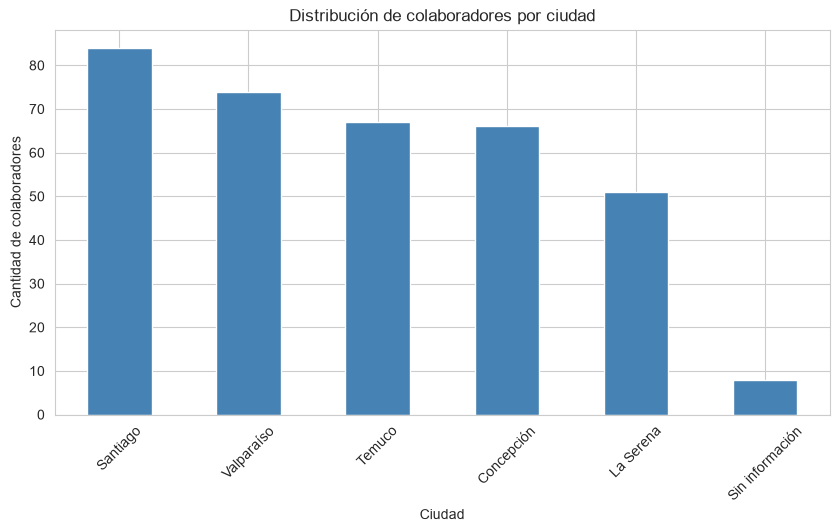

In [10]:
# P3. ¿Cómo se distribuye la cartera por ciudad?
por_ciudad = df_clean['ciudad'].value_counts()
porcentaje = df_clean['ciudad'].value_counts(normalize=True) * 100

tabla_ciudad = pd.DataFrame({'Colaboradores': por_ciudad,
                             'Porcentaje (%)': porcentaje.round(1)})
print(tabla_ciudad)

# Gráfico
por_ciudad.plot(kind='bar', color='steelblue')
plt.title('Distribución de colaboradores por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Cantidad de colaboradores')
plt.xticks(rotation=45)
plt.show()

In [11]:
# P4. ¿Cuál es el gasto mensual total del segmento?
gasto_total = df_clean['gasto_mensual'].sum()
gasto_promedio = df_clean['gasto_mensual'].mean()

print(f'Gasto mensual total:          ${gasto_total:,.0f}')
print(f'Gasto promedio por persona:   ${gasto_promedio:,.0f}')
print(f'Proyección anual (x12 meses): ${gasto_total * 12:,.0f}')

Gasto mensual total:          $110,762,978
Gasto promedio por persona:   $319,202
Proyección anual (x12 meses): $1,329,155,736


          Colaboradores  Porcentaje (%)
estado                                 
Activo              295            84.3
Inactivo             39            11.1
Licencia             16             4.6


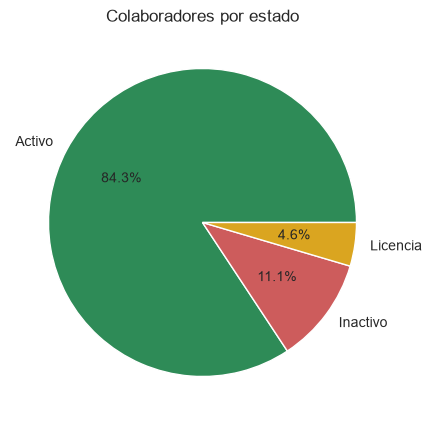

In [12]:
# P5. ¿Cuántos colaboradores están activos vs inactivos vs licencia?
por_estado = df_clean['estado'].value_counts()
porcentaje_estado = df_clean['estado'].value_counts(normalize=True) * 100

tabla_estado = pd.DataFrame({'Colaboradores': por_estado,
                             'Porcentaje (%)': porcentaje_estado.round(1)})
print(tabla_estado)

# Gráfico
por_estado.plot(kind='pie', autopct='%1.1f%%', colors=['seagreen', 'indianred', 'goldenrod'])
plt.title('Colaboradores por estado')
plt.ylabel('')
plt.show()


## 🟡 Nivel Intermedio (Preguntas 6–10)

6- P6. ¿Qué departamento concentra el mayor gasto mensual?
6- P7. ¿Qué modalidad de trabajo genera más ingreso promedio?
8- P8. ¿Cuál es el top 5 de ciudades por gasto total?
9- P9. ¿Existe relación entre satisfacción y gasto mensual?
10- P10. ¿Cómo evolucionó el ingreso promedio por año de ingreso? 

                 Gasto total  Gasto promedio  Colaboradores  % del gasto
departamento                                                            
Ventas            25291520.0        328461.0             77         23.0
Finanzas          21774235.0        315569.0             69         20.0
Marketing         21411052.0        345340.0             62         19.0
TI                20725572.0        314024.0             66         19.0
RRHH              20228690.0        297481.0             68         18.0
Sin información    1331909.0        266382.0              5          1.0

Departamento con mayor gasto: Ventas


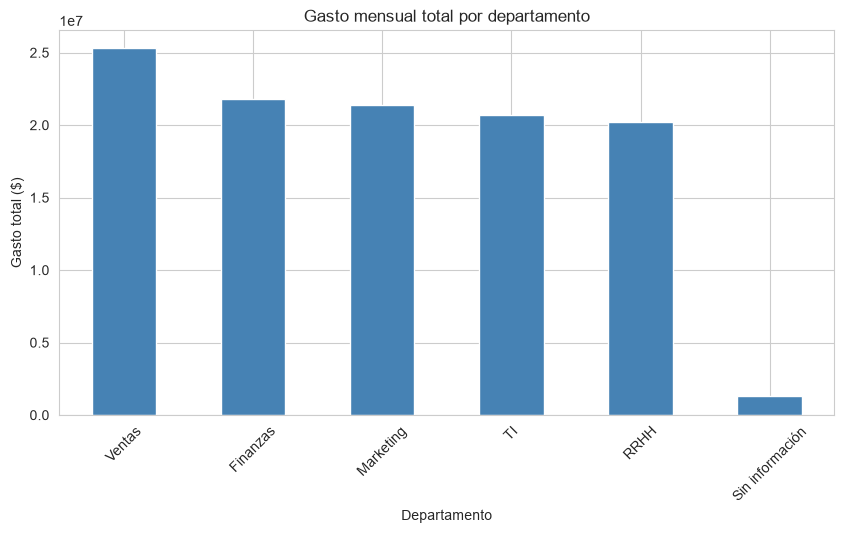

In [13]:
# ESCRIBA SUS RESPUESTA EN CADA CELDA DE CÓDIGO PARA P6 - P10

# P6. ¿Qué departamento concentra el mayor gasto mensual?
gasto_depto = df_clean.groupby('departamento')['gasto_mensual'].agg(['sum', 'mean', 'count'])
gasto_depto.columns = ['Gasto total', 'Gasto promedio', 'Colaboradores']
gasto_depto['% del gasto'] = (gasto_depto['Gasto total'] / gasto_depto['Gasto total'].sum() * 100).round(1)
gasto_depto = gasto_depto.sort_values('Gasto total', ascending=False)

print(gasto_depto.round(0))
print('\nDepartamento con mayor gasto:', gasto_depto.index[0])

# Gráfico
gasto_depto['Gasto total'].plot(kind='bar', color='steelblue')
plt.title('Gasto mensual total por departamento')
plt.xlabel('Departamento')
plt.ylabel('Gasto total ($)')
plt.xticks(rotation=45)
plt.show()

            Ingreso promedio  Ingreso mediano  Colaboradores
modalidad                                                   
Presencial         1358603.0        1315580.0            111
Híbrido            1352734.0        1417290.0            107
Remoto             1251980.0        1200270.0            114

Modalidad con mayor ingreso promedio: Presencial


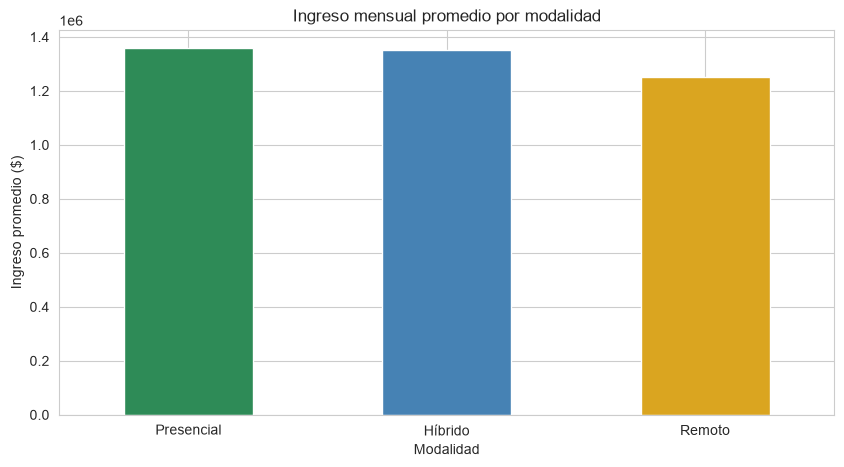

In [14]:
# P7. ¿Qué modalidad de trabajo genera más ingreso promedio?
ingreso_modalidad = df_clean.groupby('modalidad')['ingreso_mensual'].agg(['mean', 'median', 'count'])
ingreso_modalidad.columns = ['Ingreso promedio', 'Ingreso mediano', 'Colaboradores']
ingreso_modalidad = ingreso_modalidad.sort_values('Ingreso promedio', ascending=False)

print(ingreso_modalidad.round(0))
print('\nModalidad con mayor ingreso promedio:', ingreso_modalidad.index[0])

# Gráfico
ingreso_modalidad['Ingreso promedio'].plot(kind='bar', color=['seagreen', 'steelblue', 'goldenrod'])
plt.title('Ingreso mensual promedio por modalidad')
plt.xlabel('Modalidad')
plt.ylabel('Ingreso promedio ($)')
plt.xticks(rotation=0)
plt.show()

            Gasto total  Gasto promedio  Colaboradores  % del gasto
ciudad                                                             
Santiago     27417185.0        326395.0             84         25.0
Valparaíso   22291757.0        305367.0             73         20.0
Temuco       21522734.0        326102.0             66         19.0
Concepción   21329585.0        323176.0             66         19.0
La Serena    15732224.0        314644.0             50         14.0


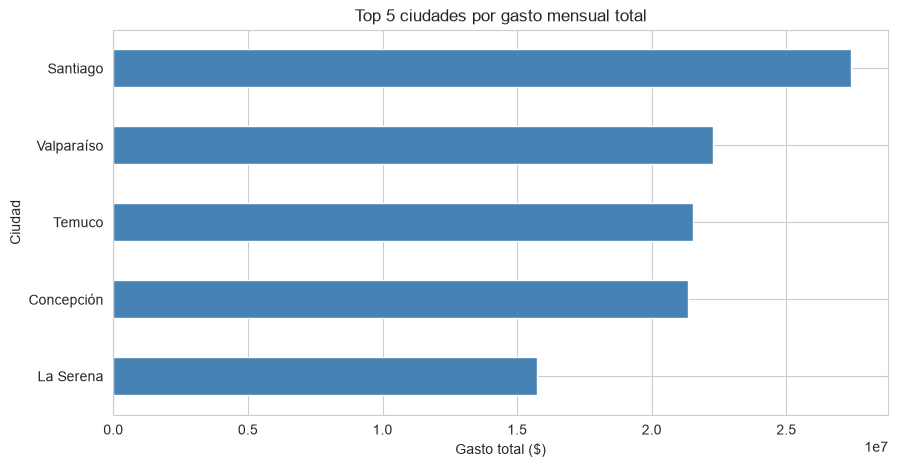

In [15]:
# P8. ¿Cuál es el top 5 de ciudades por gasto total?
gasto_ciudad = df_clean.groupby('ciudad')['gasto_mensual'].agg(['sum', 'mean', 'count'])
gasto_ciudad.columns = ['Gasto total', 'Gasto promedio', 'Colaboradores']
gasto_ciudad['% del gasto'] = (gasto_ciudad['Gasto total'] / gasto_ciudad['Gasto total'].sum() * 100).round(1)

top5_ciudades = gasto_ciudad.sort_values('Gasto total', ascending=False).head(5)
print(top5_ciudades.round(0))

# Gráfico
top5_ciudades['Gasto total'].sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 5 ciudades por gasto mensual total')
plt.xlabel('Gasto total ($)')
plt.ylabel('Ciudad')
plt.show()

Correlación satisfacción vs gasto: -0.007

Gasto promedio por nivel de satisfacción:
satisfaccion
1.0     307723.0
2.0     311902.0
3.0     360631.0
4.0     260703.0
5.0     332127.0
6.0     332008.0
7.0     379155.0
8.0     287669.0
9.0     300832.0
10.0    313270.0
Name: gasto_mensual, dtype: float64


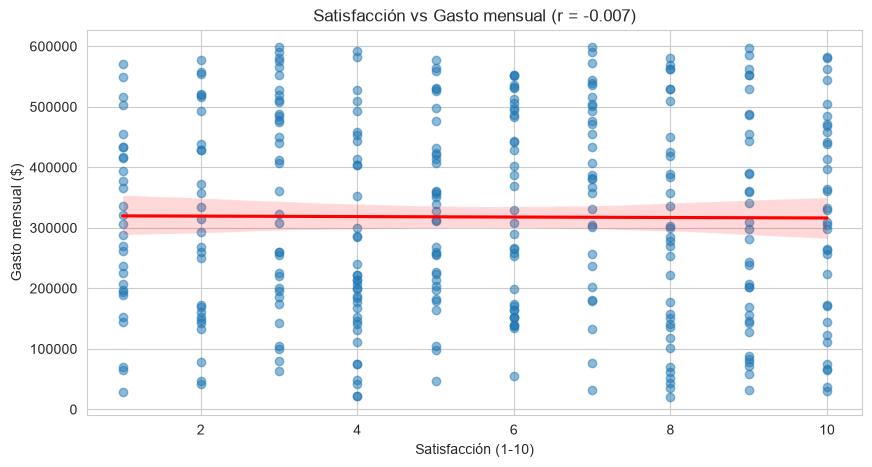

In [16]:
# P9. ¿Existe relación entre satisfacción y gasto mensual?
correlacion = df_clean['satisfaccion'].corr(df_clean['gasto_mensual'])
print(f'Correlación satisfacción vs gasto: {correlacion:.3f}')

# Gasto promedio por nivel de satisfacción
gasto_por_satisf = df_clean.groupby('satisfaccion')['gasto_mensual'].mean()
print('\nGasto promedio por nivel de satisfacción:')
print(gasto_por_satisf.round(0))

# Gráfico de dispersión
sns.regplot(data=df_clean, x='satisfaccion', y='gasto_mensual',
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title(f'Satisfacción vs Gasto mensual (r = {correlacion:.3f})')
plt.xlabel('Satisfacción (1-10)')
plt.ylabel('Gasto mensual ($)')
plt.show()

              Ingreso promedio  Colaboradores  Variación (%)
anio_ingreso                                                
2020                 1339636.0            113            NaN
2021                 1286996.0            111           -4.0
2022                 1354996.0             98            5.0


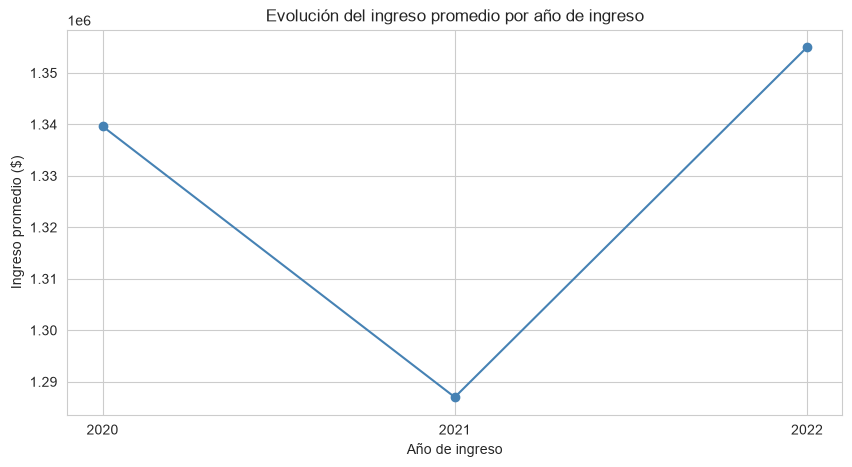

In [17]:
# P10. ¿Cómo evolucionó el ingreso promedio por año de ingreso?
ingreso_anual = df_clean.groupby('anio_ingreso')['ingreso_mensual'].agg(['mean', 'count'])
ingreso_anual.columns = ['Ingreso promedio', 'Colaboradores']
ingreso_anual.index = ingreso_anual.index.astype(int)
ingreso_anual['Variación (%)'] = (ingreso_anual['Ingreso promedio'].pct_change() * 100).round(1)

print(ingreso_anual.round(0))

# Gráfico
ingreso_anual['Ingreso promedio'].plot(kind='line', marker='o', color='steelblue')
plt.title('Evolución del ingreso promedio por año de ingreso')
plt.xlabel('Año de ingreso')
plt.ylabel('Ingreso promedio ($)')
plt.xticks(ingreso_anual.index)
plt.show()

## 🔴 Nivel Avanzado (Preguntas 11–15)

11- P11. Ranking de departamentos por evaluación promedio (¿qué área rinde mejor?)
12- P12. Segmentación por nivel de ingreso: ¿cuántos son Alto / Medio / Bajo?
13- P13. Gráfico de barras: Top 10 departamentos por gasto mensual total
14- P14. Mapa de calor: ingreso promedio por ciudad × modalidad
15- P15. Exportar el dataset limpio + resumen comercial

              Ranking  Evaluación promedio  Evaluación mediana  Colaboradores
departamento                                                                 
Finanzas            1                 4.50                 4.5             69
RRHH                2                 4.04                 3.9             69
TI                  3                 3.88                 3.7             67
Ventas              4                 3.83                 3.8             77
Marketing           5                 3.81                 3.6             63

Evaluación promedio de la empresa: 4.01
Área que rinde mejor: Finanzas


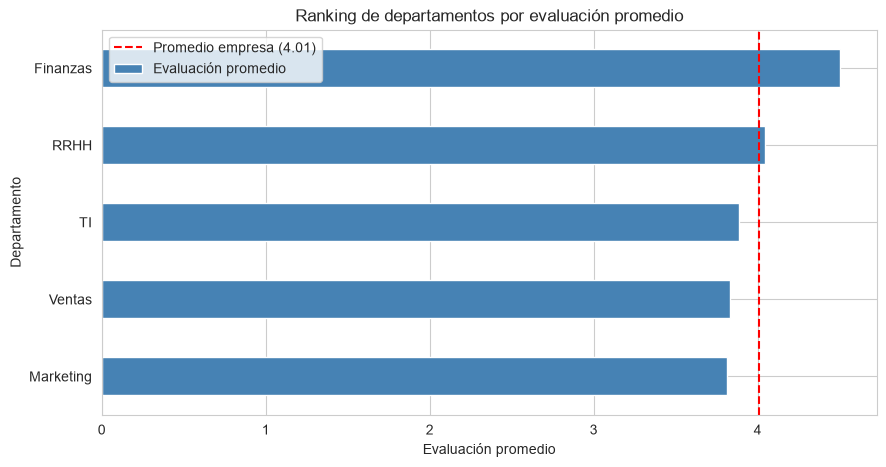

In [18]:
# P11. Ranking de departamentos por evaluación promedio (¿qué área rinde mejor?)
deptos = df_clean[df_clean['departamento'] != 'Sin información']

ranking_eval = deptos.groupby('departamento')['evaluacion'].agg(['mean', 'median', 'count'])
ranking_eval.columns = ['Evaluación promedio', 'Evaluación mediana', 'Colaboradores']
ranking_eval = ranking_eval.sort_values('Evaluación promedio', ascending=False)
ranking_eval.insert(0, 'Ranking', range(1, len(ranking_eval) + 1))

promedio_empresa = df_clean['evaluacion'].mean()
print(ranking_eval.round(2))
print(f'\nEvaluación promedio de la empresa: {promedio_empresa:.2f}')
print('Área que rinde mejor:', ranking_eval.index[0])

# Gráfico
ranking_eval['Evaluación promedio'].sort_values().plot(kind='barh', color='steelblue')
plt.axvline(promedio_empresa, color='red', linestyle='--', label=f'Promedio empresa ({promedio_empresa:.2f})')
plt.title('Ranking de departamentos por evaluación promedio')
plt.xlabel('Evaluación promedio')
plt.ylabel('Departamento')
plt.legend()
plt.show()

                  Colaboradores  Porcentaje (%)  ingreso_promedio  \
segmento_ingreso                                                    
Alto                         92            27.7         1948059.8   
Medio                       140            42.2         1335955.7   
Bajo                        100            30.1          720179.1   

                  gasto_promedio  satisfaccion_promedio  
segmento_ingreso                                         
Alto                    324668.5                    5.6  
Medio                   303849.4                    6.0  
Bajo                    325715.0                    5.1  

Sin dato de ingreso: 18


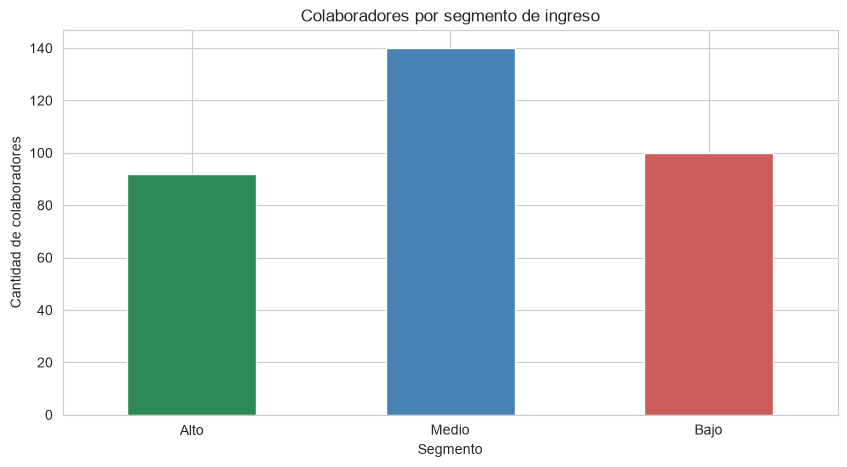

In [19]:
# P12. Segmentación por nivel de ingreso: ¿cuántos son Alto / Medio / Bajo?
df_clean['segmento_ingreso'] = pd.cut(df_clean['ingreso_mensual'],
                                      bins=[0, 1_000_000, 1_700_000, np.inf],
                                      labels=['Bajo', 'Medio', 'Alto'],
                                      right=False)

conteo = df_clean['segmento_ingreso'].value_counts().reindex(['Alto', 'Medio', 'Bajo'])
porcentaje_seg = (conteo / conteo.sum() * 100).round(1)

resumen_seg = df_clean.groupby('segmento_ingreso', observed=True).agg(
    ingreso_promedio=('ingreso_mensual', 'mean'),
    gasto_promedio=('gasto_mensual', 'mean'),
    satisfaccion_promedio=('satisfaccion', 'mean')
).reindex(['Alto', 'Medio', 'Bajo'])

resumen_seg.insert(0, 'Colaboradores', conteo)
resumen_seg.insert(1, 'Porcentaje (%)', porcentaje_seg)
print(resumen_seg.round(1))
print('\nSin dato de ingreso:', df_clean['segmento_ingreso'].isnull().sum())

# Gráfico
conteo.plot(kind='bar', color=['seagreen', 'steelblue', 'indianred'])
plt.title('Colaboradores por segmento de ingreso')
plt.xlabel('Segmento')
plt.ylabel('Cantidad de colaboradores')
plt.xticks(rotation=0)
plt.show()

              Gasto total  % del gasto  % acumulado
departamento                                       
Ventas         25291520.0         23.1         23.1
Finanzas       21774235.0         19.9         43.0
Marketing      21411052.0         19.6         62.6
TI             20725572.0         18.9         81.5
RRHH           20228690.0         18.5        100.0


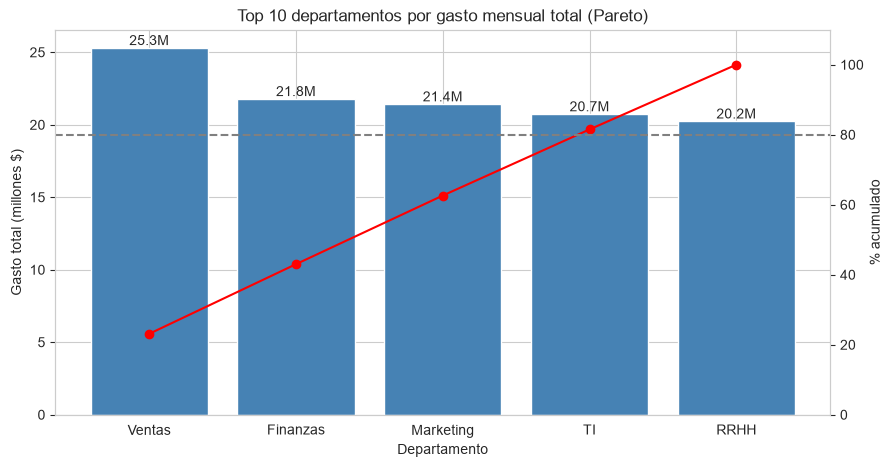

In [20]:
# P13. Gráfico de barras: Top 10 departamentos por gasto mensual total
deptos = df_clean[df_clean['departamento'] != 'Sin información']

top10_deptos = (deptos.groupby('departamento')['gasto_mensual']
                .sum()
                .sort_values(ascending=False)
                .head(10))

pareto = pd.DataFrame({'Gasto total': top10_deptos})
pareto['% del gasto'] = (pareto['Gasto total'] / pareto['Gasto total'].sum() * 100).round(1)
pareto['% acumulado'] = pareto['% del gasto'].cumsum().round(1)
print(pareto)

# Gráfico de barras + línea de Pareto
fig, ax1 = plt.subplots()
ax1.bar(pareto.index, pareto['Gasto total'] / 1_000_000, color='steelblue')
ax1.set_xlabel('Departamento')
ax1.set_ylabel('Gasto total (millones $)')

for i, valor in enumerate(pareto['Gasto total'] / 1_000_000):
    ax1.text(i, valor, f'{valor:.1f}M', ha='center', va='bottom')

ax2 = ax1.twinx()
ax2.plot(pareto.index, pareto['% acumulado'], color='red', marker='o')
ax2.axhline(80, color='gray', linestyle='--')
ax2.set_ylabel('% acumulado')
ax2.set_ylim(0, 110)
ax2.grid(False)

plt.title('Top 10 departamentos por gasto mensual total (Pareto)')
plt.show()

modalidad   Híbrido  Presencial  Remoto
ciudad                                 
Concepción   1407.0      1354.0  1331.0
La Serena    1310.0      1437.0  1356.0
Santiago     1366.0      1357.0  1217.0
Temuco       1314.0      1408.0  1176.0
Valparaíso   1402.0      1320.0  1169.0


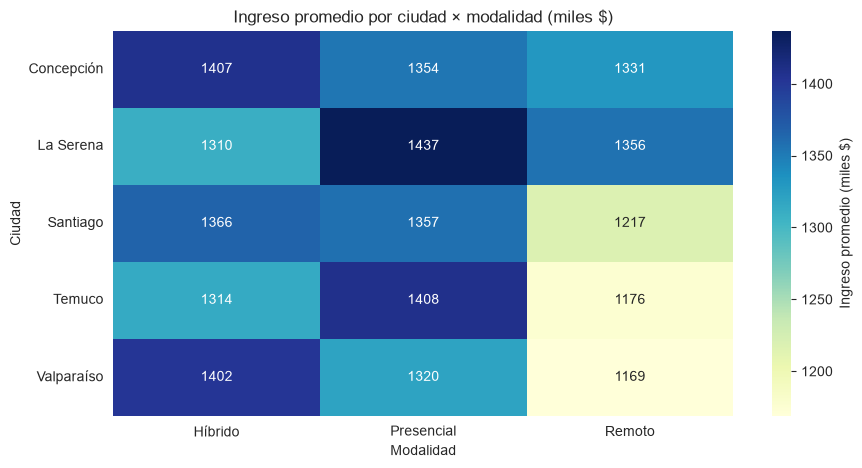


Mejor combinación: ('La Serena', 'Presencial') → $1,436,824
Peor combinación:  ('Valparaíso', 'Remoto') → $1,168,978


In [21]:
# P14. Mapa de calor: ingreso promedio por ciudad × modalidad
ciudades = df_clean[df_clean['ciudad'] != 'Sin información']

tabla_calor = ciudades.pivot_table(index='ciudad',
                                   columns='modalidad',
                                   values='ingreso_mensual',
                                   aggfunc='mean')
print((tabla_calor / 1000).round(0))

# Mapa de calor (valores en miles de $)
sns.heatmap(tabla_calor / 1000, annot=True, fmt='.0f', cmap='YlGnBu',
            cbar_kws={'label': 'Ingreso promedio (miles $)'})
plt.title('Ingreso promedio por ciudad × modalidad (miles $)')
plt.xlabel('Modalidad')
plt.ylabel('Ciudad')
plt.yticks(rotation=0)
plt.show()

# Mejor y peor combinación
combinaciones = tabla_calor.stack().sort_values(ascending=False)
print(f'\nMejor combinación: {combinaciones.index[0]} → ${combinaciones.iloc[0]:,.0f}')
print(f'Peor combinación:  {combinaciones.index[-1]} → ${combinaciones.iloc[-1]:,.0f}')

In [22]:
# P15. Exportar el dataset limpio + resumen comercial
carpeta = r'C:\Users\Vale\Desktop\ingenieria comercial\semestre 6\desicion y simulacion'

# 1. Resumen comercial: indicadores clave
resumen = pd.DataFrame({
    'Indicador': [
        'Colaboradores únicos',
        'Ingreso mensual promedio ($)',
        'Gasto mensual total ($)',
        'Gasto mensual promedio ($)',
        'Colaboradores activos (%)',
        'Departamento con mayor gasto',
        'Modalidad con mayor ingreso promedio',
        'Ciudad con mayor gasto',
        'Correlación satisfacción vs gasto',
        'Departamento con mejor evaluación',
    ],
    'Valor': [
        df_clean['id'].nunique(),
        round(df_clean['ingreso_mensual'].mean()),
        round(df_clean['gasto_mensual'].sum()),
        round(df_clean['gasto_mensual'].mean()),
        round((df_clean['estado'] == 'Activo').mean() * 100, 1),
        df_clean.groupby('departamento')['gasto_mensual'].sum().idxmax(),
        df_clean.groupby('modalidad')['ingreso_mensual'].mean().idxmax(),
        df_clean.groupby('ciudad')['gasto_mensual'].sum().idxmax(),
        round(df_clean['satisfaccion'].corr(df_clean['gasto_mensual']), 3),
        df_clean.groupby('departamento')['evaluacion'].mean().idxmax(),
    ]
})
print('=== RESUMEN COMERCIAL ===')
print(resumen.to_string(index=False))

# 2. Tablas de apoyo
por_depto = df_clean.groupby('departamento').agg(
    colaboradores=('id', 'count'),
    gasto_total=('gasto_mensual', 'sum'),
    ingreso_promedio=('ingreso_mensual', 'mean'),
    evaluacion_promedio=('evaluacion', 'mean')
).round(1).sort_values('gasto_total', ascending=False)

por_ciudad = df_clean.groupby('ciudad').agg(
    colaboradores=('id', 'count'),
    gasto_total=('gasto_mensual', 'sum'),
    ingreso_promedio=('ingreso_mensual', 'mean')
).round(1).sort_values('gasto_total', ascending=False)

# 3. Exportar a Excel (una hoja por tabla) y a CSV
ruta_excel = os.path.join(carpeta, 'Dataset_S7_limpio.xlsx')
with pd.ExcelWriter(ruta_excel) as writer:
    df_clean.to_excel(writer, sheet_name='Dataset limpio', index=False)
    resumen.to_excel(writer, sheet_name='Resumen comercial', index=False)
    por_depto.to_excel(writer, sheet_name='Por departamento')
    por_ciudad.to_excel(writer, sheet_name='Por ciudad')

ruta_csv = os.path.join(carpeta, 'Dataset_S7_limpio.csv')
df_clean.to_csv(ruta_csv, index=False, encoding='utf-8-sig')

print('\nArchivos exportados:')
print(' -', ruta_excel)
print(' -', ruta_csv)
print('Filas exportadas:', df_clean.shape[0], '| Columnas:', df_clean.shape[1])

=== RESUMEN COMERCIAL ===
                           Indicador      Valor
                Colaboradores únicos        350
        Ingreso mensual promedio ($)    1320100
             Gasto mensual total ($)  110762978
          Gasto mensual promedio ($)     319202
           Colaboradores activos (%)       84.3
        Departamento con mayor gasto     Ventas
Modalidad con mayor ingreso promedio Presencial
              Ciudad con mayor gasto   Santiago
   Correlación satisfacción vs gasto     -0.007
   Departamento con mejor evaluación   Finanzas

Archivos exportados:
 - C:\Users\Vale\Desktop\ingenieria comercial\semestre 6\desicion y simulacion\Dataset_S7_limpio.xlsx
 - C:\Users\Vale\Desktop\ingenieria comercial\semestre 6\desicion y simulacion\Dataset_S7_limpio.csv
Filas exportadas: 350 | Columnas: 20
